## 1. Imports, Data Recovery & Pipeline Rebuild

### 🎯 Objectives:
1. Reload the dataset and re-create the exact stratified 60% Train / 20% Val / 20% Test splits (`random_state=42`).
2. Rebuild the `ColumnTransformer` preprocessor and the `evaluate_model` helper.
3. Re-train the default Random Forest baseline so tuning gains are measured fairly.

### 💡 Conceptual Explanation & Intuition:
- **Why rebuild from scratch?** Tuning must start from the *identical* data lineage as Stage 4/5. Any change in `random_state` or `stratify` would shuffle rows between splits and make tuned-vs-baseline comparisons meaningless.
- **What is a hyperparameter?** A setting you choose *before* training (e.g. `n_estimators=100`, `max_depth=10`) as opposed to a learned parameter (e.g. tree split thresholds, logistic weights). Tuning searches the hyperparameter space for the configuration with the best cross-validated Macro F1.

This starter cell is ready to run — no coding required.

> ⚠️ **Jupyter display rule:** only the *last* bare expression (e.g. `df.head()`) in a cell is auto-shown. Everything else must use explicit `print(...)` for text or `display(...)` for DataFrames/plots. That is why the starter cell below uses `print()` + `display()` for each output.


In [18]:
# --- Predefined imports, paths, and configurations ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

# 1. Load and clean column names
DATA_PATH = "../data/mental_health_analysis.csv"
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.lower().str.replace(" ", "_")

# 2. Features, target, zero-indexing
target_col = "survey_stress_score"
dropped_cols = ["user_id", "wearable_stress_score", target_col]
numerical_cols = ["age", "social_media_hours", "exercise_hours", "sleep_hours", "screen_time_hours"]
categorical_cols = ["gender", "support_system", "academic_performance"]
X = df.drop(columns=dropped_cols)
y = df[target_col] - 1  # 0..4 for XGBoost compatibility
label_mapping = {0: 1, 1: 2, 2: 3, 3: 4, 4: 5}

# 3. Stratified 60/20/20 split (identical to notebook 03)
RANDOM_STATE = 42
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=RANDOM_STATE)

# 4. Preprocessor + evaluation helper
preprocessor = ColumnTransformer(transformers=[("num", StandardScaler(), numerical_cols), ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)])
target_names = ["Level 1", "Level 2", "Level 3", "Level 4", "Level 5"]
display_labels = ["Lvl 1", "Lvl 2", "Lvl 3", "Lvl 4", "Lvl 5"]

def evaluate_model(y_true, y_pred, model_name="Model", display_cm=True):
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    weighted_f1 = f1_score(y_true, y_pred, average="weighted")
    print(f"=== {model_name} Evaluation ===")
    print(f"Accuracy:     {acc:.4f}")
    print(f"Macro F1:     {macro_f1:.4f} (Primary Metric)")
    print(f"Weighted F1:  {weighted_f1:.4f}")
    print("\nClassification Report:")
    display(classification_report(y_true, y_pred, target_names=target_names))
    if display_cm:
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=display_labels, cmap="Blues", ax=ax)
        ax.set_title(f"Confusion Matrix \u2014 {model_name}")
        plt.grid(False)
        plt.show()
    return {"model": model_name, "accuracy": round(acc, 4), "macro_f1": round(macro_f1, 4), "weighted_f1": round(weighted_f1, 4)}

print(f"Dataset ready: Train={X_train.shape}, Val={X_val.shape}, Test={X_test.shape}")
print(f"Features ({X.shape[1]}): {list(X.columns)}")
print("Target balance (full data):", pd.Series(y).value_counts(normalize=True).sort_index().round(3).to_dict())
display(df.head(10))  # display() renders DataFrames; bare df.head() would only show if it is the LAST line


Dataset ready: Train=(3000, 8), Val=(1000, 8), Test=(1000, 8)
Features (8): ['age', 'gender', 'social_media_hours', 'exercise_hours', 'sleep_hours', 'screen_time_hours', 'support_system', 'academic_performance']
Target balance (full data): {0: 0.196, 1: 0.201, 2: 0.197, 3: 0.202, 4: 0.203}


,user_id,age,gender,social_media_hours,exercise_hours,sleep_hours,screen_time_hours,survey_stress_score,wearable_stress_score,support_system,academic_performance
0,1,16,F,9.654486,2.458001,5.198926,8.158189,3,0.288962,Moderate,Excellent
1,2,17,M,9.158143,0.392095,8.866097,5.151993,5,0.409446,Moderate,Good
2,3,15,M,5.028755,0.520119,4.943095,9.209325,2,0.423837,Moderate,Poor
3,4,17,F,7.951103,1.022630,5.262773,9.823658,5,0.666021,Moderate,Average
4,5,17,F,1.357459,1.225462,6.196080,11.338990,5,0.928060,High,Poor
5,6,14,M,9.774382,1.046108,9.282089,5.677747,5,0.070586,Low,Poor
6,7,15,F,9.643532,2.290941,4.790720,8.860167,4,0.953354,Low,Excellent
7,8,15,F,1.637290,0.290854,4.733405,8.026163,4,0.910201,Moderate,Poor
8,9,15,M,2.994231,1.053651,6.963850,7.252061,5,0.117732,Low,Poor
9,10,17,M,1.001550,2.511720,5.658463,10.904165,2,0.183585,Moderate,Good


---
## 2. Stratified K-Fold & Search Strategy

### 🎯 Objectives:
1. Create a `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` splitter.
2. Understand when to use `GridSearchCV` (exhaustive, small grids) vs `RandomizedSearchCV` (sampled, large spaces).

### 💡 Conceptual Explanation & Intuition:
- **Why not tune on the Validation set directly?** Repeatedly tweaking hyperparameters against the same Validation set leaks information: the Validation score becomes optimistic. **K-Fold Cross-Validation** instead splits the *training* data into $K$ folds (here $K=5$), trains on $K-1$ folds and validates on the held-out fold, rotating $K$ times. The mean score $\bar{s} = \frac{1}{K}\sum_{k=1}^K s_k$ is a far more stable estimate of generalization.
- **Why Stratified?** Plain `KFold` can randomly starve a fold of a rare class. `StratifiedKFold` forces every fold to preserve the ~20%-per-class balance, which is critical for our 5 balanced stress levels.
- **Grid vs Random search:** `GridSearchCV` evaluates *every* combination in `param_grid` (e.g. $2 \times 3 \times 2 = 12$ fits $\times$ 5 folds $= 60$ trainings) \u2014 thorough but expensive. `RandomizedSearchCV` samples `n_iter` random combinations \u2014 cheaper for large spaces such as XGBoost (`n_estimators` $\times$ `max_depth` $\times$ `learning_rate` $\times$ `subsample` ...).
- **Scoring:** We pass `scoring='f1_macro'` so the search optimises our primary metric, not default accuracy.

### 🛠️ Useful Functions:
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` \u2014 the CV splitter.
- `GridSearchCV(estimator, param_grid, cv=cv, scoring='f1_macro', n_jobs=-1)` \u2014 exhaustive search.
- `RandomizedSearchCV(estimator, param_distributions, n_iter=20, cv=cv, scoring='f1_macro', random_state=42, n_jobs=-1)` \u2014 sampled search.

In [19]:
# --- Predefined CV configuration ---
CV_N_SPLITS = 5
CV_SHUFFLE = True
CV_SCORING = "f1_macro"
CV_RANDOM_STATE = 42

# YOUR CODE HERE:
# 1. Create a StratifiedKFold splitter named cv using the predefined variables above
# cv = StratifiedKFold(...)  # TODO: fill n_splits, shuffle, random_state
cv = StratifiedKFold(n_splits=CV_N_SPLITS, shuffle=CV_SHUFFLE, random_state=CV_RANDOM_STATE)

# 2. Test invocation: show ALL 5 folds (no break) with explicit print() per fold
# NOTE: Jupyter auto-shows only the LAST bare expression, so we print() inside the loop.
print(f"CV strategy: {cv}")
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
    val_balance = pd.Series(np.asarray(y_train)[val_idx]).value_counts(normalize=True).sort_index().round(3).to_dict()
    print(f"Fold-{fold}: train={len(train_idx)} | val={len(val_idx)} | val balance={val_balance}")


CV strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Fold-1: train=2400 | val=600 | val balance={0: 0.195, 1: 0.202, 2: 0.198, 3: 0.202, 4: 0.203}
Fold-2: train=2400 | val=600 | val balance={0: 0.197, 1: 0.2, 2: 0.198, 3: 0.202, 4: 0.203}
Fold-3: train=2400 | val=600 | val balance={0: 0.197, 1: 0.2, 2: 0.197, 3: 0.203, 4: 0.203}
Fold-4: train=2400 | val=600 | val balance={0: 0.197, 1: 0.2, 2: 0.197, 3: 0.203, 4: 0.203}
Fold-5: train=2400 | val=600 | val balance={0: 0.197, 1: 0.202, 2: 0.197, 3: 0.202, 4: 0.203}


---
## 3. Define the Hyperparameter Search Space

### 🎯 Objectives:
1. Write a `rf_param_grid` dictionary for the Random Forest pipeline (primary tuning target).
2. (Optional extension) Write an `xgb_param_dist` dictionary for XGBoost + `RandomizedSearchCV`.

### 💡 Conceptual Explanation & Intuition:
- **What each Random Forest knob actually does:**
  - `classifier__n_estimators` (e.g. `[100, 200]`): number of trees $B$ in $P(y=k|x) = \frac{1}{B}\sum_b P_b(y=k|x)$. More trees reduce variance but cost compute linearly.
  - `classifier__max_depth` (e.g. `[None, 10, 20]`): maximum root-to-leaf depth. `None` = unlimited (low bias, high variance); small values regularize by forcing simpler rules.
  - `classifier__min_samples_split` (e.g. `[2, 5]`): minimum samples required to split a node. Larger values stop the tree from chasing single noisy rows.
- **Why the `classifier__` prefix?** Inside a `Pipeline(steps=[('preprocessor', ...), ('classifier', ...)])`, `GridSearchCV` addresses nested estimator parameters as `<step_name>__<param>`. Forgetting the prefix is the #1 tuning bug.
- **What each XGBoost knob does:** `n_estimators` (boosting rounds), `max_depth` (tree complexity), `learning_rate` $\eta$ in $\hat{y}^{(t)} = \hat{y}^{(t-1)} + \eta f_t(x)$ (small $\eta$ = slower, safer learning), `subsample` (row fraction per tree, e.g. 0.8 decorrelates trees).

### 🛠️ Useful Functions / Patterns:
- Plain dict of lists for `GridSearchCV`: `{"classifier__n_estimators": [100, 200], ...}`.
- Dict of lists/distributions for `RandomizedSearchCV` with `n_iter=...`.


In [21]:
# --- Predefined candidate values (use these exact lists) ---
RF_N_ESTIMATORS_CHOICES = [100, 200]
RF_MAX_DEPTH_CHOICES = [None, 10, 20]
RF_MIN_SPLIT_CHOICES = [2, 5]
XGB_N_ESTIMATORS_CHOICES = [100, 200, 300]
XGB_MAX_DEPTH_CHOICES = [3, 4, 6]
XGB_LR_CHOICES = [0.05, 0.1]
XGB_SUBSAMPLE_CHOICES = [0.8, 1.0]



rf_param_grid = {
    'classifier__n_estimators': RF_N_ESTIMATORS_CHOICES,
    'classifier__max_depth': RF_MAX_DEPTH_CHOICES,
    'classifier__min_samples_split': RF_MIN_SPLIT_CHOICES
}

xgb_param_dist = {
    'classifier__n_estimators': XGB_N_ESTIMATORS_CHOICES,
    'classifier__max_depth': XGB_MAX_DEPTH_CHOICES,
    'classifier__learning_rate': XGB_LR_CHOICES,
    'classifier__subsample': XGB_SUBSAMPLE_CHOICES
}

# YOUR CODE HERE:
# 1. Build rf_param_grid for GridSearchCV using the RF_*_CHOICES lists above
# rf_param_grid = {...}  # keys: 'classifier__n_estimators', 'classifier__max_depth', 'classifier__min_samples_split'

# 2. (Optional) Build xgb_param_dist for RandomizedSearchCV using the XGB_*_CHOICES lists
# xgb_param_dist = {...}  # keys: 'classifier__n_estimators', 'classifier__max_depth', 'classifier__learning_rate', 'classifier__subsample'

# 3. Test invocation: print grid size (number of combinations)
# import math
# print("RF grid combos:", math.prod([len(v) for v in rf_param_grid.values()]))

print("RF grid combos:", len(RF_N_ESTIMATORS_CHOICES) * len(RF_MAX_DEPTH_CHOICES) * len(RF_MIN_SPLIT_CHOICES))

RF grid combos: 12


---
## 4. Run GridSearchCV Tuning

### 🎯 Objectives:
1. Wrap `preprocessor + RandomForestClassifier` in a `Pipeline` and tune it with `GridSearchCV`.
2. Report `best_params_`, `best_score_` (mean CV Macro F1), and the Validation score of the refit best estimator.

### 💡 Conceptual Explanation & Intuition:
- **What `GridSearchCV.fit` actually does:** For each of the 12 combos it runs 5-fold CV (60 trainings), records `mean_test_score` and `std_test_score` in `cv_results_`, then **refits** the single best combo on the *full* `X_train` (`refit=True` default). `best_estimator_` is therefore immediately usable for prediction.
- **Why `n_jobs=-1`?** Uses all CPU cores; 60 fits run in parallel instead of serially.
- **Why `scoring='f1_macro'`?** Guarantees the winner optimises equal-weight performance across all 5 stress levels, consistent with notebook 02/03.

### 🛠️ Useful Functions:
- `Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(random_state=42))])`
- `GridSearchCV(estimator=rf_pipeline, param_grid=rf_param_grid, cv=cv, scoring='f1_macro', n_jobs=-1, verbose=1)`
- `.fit(X_train, y_train)`, `.best_params_`, `.best_score_`, `.predict(X_val)`

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best params: {'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best mean CV Macro F1: 0.2039
=== Random Forest (Tuned) Evaluation ===
Accuracy:     0.1930
Macro F1:     0.1930 (Primary Metric)
Weighted F1:  0.1931

Classification Report:


'              precision    recall  f1-score   support\n\n     Level 1       0.17      0.20      0.18       196\n     Level 2       0.19      0.17      0.18       201\n     Level 3       0.20      0.18      0.19       197\n     Level 4       0.22      0.22      0.22       202\n     Level 5       0.19      0.20      0.19       204\n\n    accuracy                           0.19      1000\n   macro avg       0.19      0.19      0.19      1000\nweighted avg       0.19      0.19      0.19      1000\n'

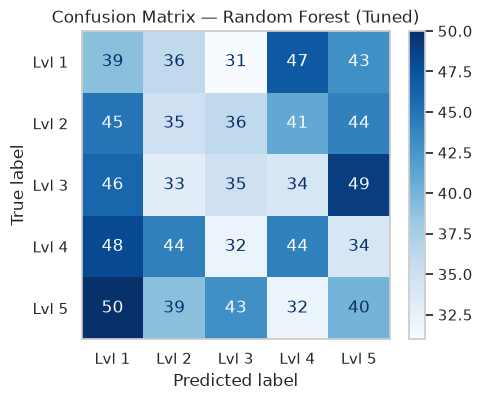

In [27]:
# --- Predefined search plumbing ---
RF_BASELINE = RandomForestClassifier(random_state=42, n_jobs=-1)
GRID_N_JOBS = -1
GRID_VERBOSE = 1

# YOUR CODE HERE:
# 1. Build the untuned pipeline (preprocessor + RF_BASELINE)
# rf_pipeline = Pipeline(steps=[...])
rf_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", RF_BASELINE)])

# 2. Build grid_search = GridSearchCV(estimator=rf_pipeline, param_grid=rf_param_grid, cv=cv, scoring=CV_SCORING, n_jobs=GRID_N_JOBS, verbose=GRID_VERBOSE)
# grid_search = None  # TODO

grid_search = GridSearchCV(estimator=rf_pipeline, param_grid=rf_param_grid, cv=cv, scoring=CV_SCORING, n_jobs=GRID_N_JOBS, verbose=GRID_VERBOSE)

# 3. Fit on (X_train, y_train) and report best params / best CV score
# grid_search.fit(X_train, y_train)
# print("Best params:", grid_search.best_params_)
# print(f"Best mean CV Macro F1: {grid_search.best_score_:.4f}")


grid_search.fit(X_train, y_train)
print("Best params:", grid_search.best_params_)
print(f"Best mean CV Macro F1: {grid_search.best_score_:.4f}")

# 4. Test invocation: predict on X_val with the refit best estimator and evaluate
# y_val_pred_tuned = grid_search.predict(X_val)
# tuned_results = evaluate_model(y_val, y_val_pred_tuned, model_name="Random Forest (Tuned)")

y_val_pred_tuned = grid_search.predict(X_val)
tuned_results = evaluate_model(y_val, y_val_pred_tuned, model_name="Random Forest (Tuned)")

---
## 5. Overfitting Check: Train vs Validation Gap

### 🎯 Objectives:
1. Score the tuned model on **Train** and **Validation** (Accuracy + Macro F1).
2. Decide whether the model overfits, underfits, or generalises well.

### 💡 Conceptual Explanation & Intuition:
- **What is overfitting?** The model memorises training noise instead of learning transferable patterns: $\text{F1}_{train} \gg \text{F1}_{val}$ (large gap, e.g. > 0.10). An unconstrained tree often hits ~1.00 train F1 but ~0.20 val F1.
- **What is underfitting?** Both scores are low and close together ($\text{F1}_{train} \approx \text{F1}_{val} \approx$ poor): the model is too simple (e.g. `max_depth=2`) to capture real structure.
- **Healthy generalisation:** Train slightly above Val (gap $\approx$ 0.02\u20130.05) with the best absolute Val score. If the gap is huge, strengthen regularization (`max_depth` down, `min_samples_split` up); if both are poor, add capacity.

### 🛠️ Useful Functions:
- `grid_search.score(X_train, y_train)` uses the refit scorer (`f1_macro`) \u2014 or compute `f1_score(..., average='macro')` explicitly.
- Compare against the default (untuned) RF and the Logistic Regression baseline from notebook 03.

In [29]:
# --- Predefined comparison labels ---
GAP_WARN_THRESHOLD = 0.10  # gap above this suggests overfitting

from sklearn.metrics import f1_score
y_train_pred_tuned = grid_search.predict(X_train)
train_f1 = f1_score(y_train, y_train_pred_tuned, average="macro")
val_f1 = f1_score(y_val, y_val_pred_tuned, average="macro")
print(f"Train Macro F1: {train_f1:.4f} | Val Macro F1: {val_f1:.4f} | Gap: {train_f1 - val_f1:.4f}")
# YOUR CODE HERE:
# 1. Compute train + val Macro F1 for the tuned model
# from sklearn.metrics import f1_score
# y_train_pred_tuned = grid_search.predict(X_train)
# train_f1 = f1_score(y_train, y_train_pred_tuned, average="macro")
# val_f1 = f1_score(y_val, y_val_pred_tuned, average="macro")
# print(f"Train Macro F1: {train_f1:.4f} | Val Macro F1: {val_f1:.4f} | Gap: {train_f1 - val_f1:.4f}")

from sklearn.metrics import f1_score
t_train_pred_tuned = grid_search.predict(X_train)
train_f1 = f1_score(y_train, t_train_pred_tuned, average="macro")
val_f1 = f1_score(y_val, y_val_pred_tuned, average="macro")
print(f"Train Macro F1: {train_f1:.4f} | Val Macro F1: {val_f1:.4f} | Gap: {train_f1 - val_f1:.4f}")

gap = train_f1 - val_f1
print("Overfitting suspected!" if gap > GAP_WARN_THRESHOLD else "Generalisation looks OK.")

# 2. Test invocation: diagnosis message based on GAP_WARN_THRESHOLD
# gap = train_f1 - val_f1
# print("Overfitting suspected!" if gap > GAP_WARN_THRESHOLD else "Generalisation looks OK.")


Train Macro F1: 1.0000 | Val Macro F1: 0.1930 | Gap: 0.8070
Train Macro F1: 1.0000 | Val Macro F1: 0.1930 | Gap: 0.8070
Overfitting suspected!


---
## 6. Final Evaluation on the Locked Test Set

### 🎯 Objectives:
1. Evaluate the tuned `best_estimator_` **once** on `X_test`.
2. Save the Test metrics dict for the README / production notebook.

### 💡 Conceptual Explanation & Intuition:
- **Why the Test set is a vault:** Validation was used (indirectly, via CV + model selection) to *choose* hyperparameters, so Val scores are now slightly optimistic. The Test set has never influenced any decision, so its score is the only unbiased estimate of real-world performance: $\text{Test F1} \approx$ future performance.
- **Run-once rule:** Every extra peek-and-tweak cycle turns Test into a second Validation set. Evaluate once, record, and freeze the model.

### 🛠️ Useful Functions:
- `grid_search.predict(X_test)` then `evaluate_model(y_test, y_pred, model_name=...)`.
- Store the returned dict as `final_test_metrics`.

=== Random Forest (Tuned, Test) Evaluation ===
Accuracy:     0.2010
Macro F1:     0.2012 (Primary Metric)
Weighted F1:  0.2010

Classification Report:


'              precision    recall  f1-score   support\n\n     Level 1       0.22      0.19      0.20       196\n     Level 2       0.20      0.22      0.21       201\n     Level 3       0.23      0.23      0.23       198\n     Level 4       0.18      0.19      0.18       202\n     Level 5       0.18      0.18      0.18       203\n\n    accuracy                           0.20      1000\n   macro avg       0.20      0.20      0.20      1000\nweighted avg       0.20      0.20      0.20      1000\n'

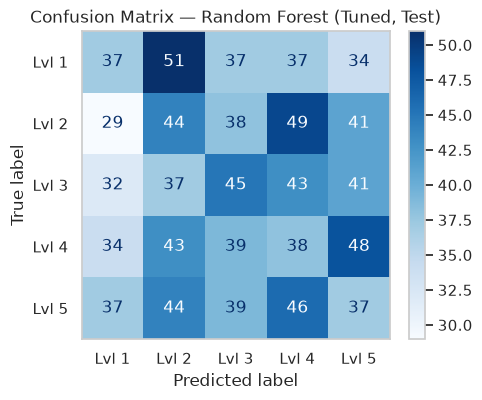

{'model': 'Random Forest (Tuned, Test)', 'accuracy': 0.201, 'macro_f1': 0.2012, 'weighted_f1': 0.201}


In [30]:
# --- Predefined final-test label ---
FINAL_MODEL_NAME = "Random Forest (Tuned, Test)"

y_test_pred = grid_search.predict(X_test)
final_test_metrics = evaluate_model(y_test, y_test_pred, model_name=FINAL_MODEL_NAME)
print(final_test_metrics)
# YOUR CODE HERE:
# 1. Predict on the locked Test set with the tuned best estimator (RUN ONCE)
# y_test_pred = grid_search.predict(X_test)
# final_test_metrics = evaluate_model(y_test, y_test_pred, model_name=FINAL_MODEL_NAME)
# print(final_test_metrics)


---
## 7. Feature Importance Analysis

### 🎯 Objectives:
1. Extract impurity-based `feature_importances_` from the tuned forest and map them to human-readable feature names.
2. Confirm with `permutation_importance` (model-agnostic) on the Validation set.
3. Name the top-3 most predictive lifestyle factors.

### 💡 Conceptual Explanation & Intuition:
- **Impurity importance (`feature_importances_`):** Each time a feature splits a node it reduces Gini impurity $I_G = 1 - \sum_k p_k^2$ by some amount weighted by node size. Summing these reductions over all trees and normalising gives $\sum_j importance_j = 1$. Fast but biased toward high-cardinality / continuous features.
- **Permutation importance:** Randomly shuffles one column of `X_val` and measures the drop in Macro F1: $importance_j = s_{baseline} - s_{shuffled\_j}$. Model-agnostic and honest about what the model *relies on*, but slower (requires $D$ re-evaluations).
- **Getting names right:** After `ColumnTransformer`, numeric names stay as-is but categoricals expand (e.g. `support_system_Moderate`). Use `preprocessor.get_feature_names_out()` via the fitted `best_estimator_`.

### 🛠️ Useful Functions:
- `grid_search.best_estimator_.named_steps['classifier'].feature_importances_`
- `grid_search.best_estimator_.named_steps['preprocessor'].get_feature_names_out()`
- `permutation_importance(estimator, X_val, y_val, n_repeats=10, scoring='f1_macro', random_state=42)`

  feature  importance
0       a         0.7
1       b         0.3


,feature,importance
3,num__sleep_hours,0.193410
1,num__social_media_hours,0.190642
4,num__screen_time_hours,0.189585
2,num__exercise_hours,0.188770
0,num__age,0.087723
8,cat__support_system_Low,0.018038
7,cat__support_system_High,0.017694
12,cat__academic_performance_Good,0.017293
9,cat__support_system_Moderate,0.016854
6,cat__gender_M,0.016590


/tmp/ipykernel_73322/2034689973.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=impurity_df, x='importance', y='feature', palette='mako', ax=ax)


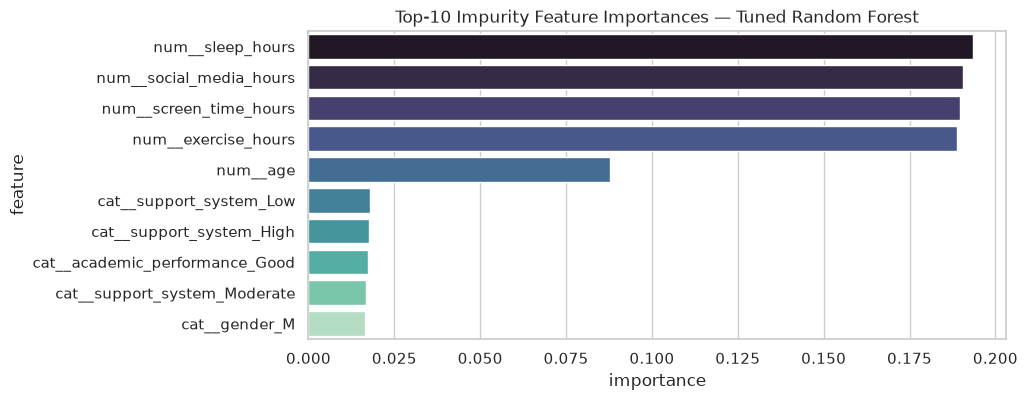

,feature,importance
5,screen_time_hours,0.005142
4,sleep_hours,0.002939
6,support_system,0.000574
1,gender,-0.000326
3,exercise_hours,-0.000932
0,age,-0.002767
7,academic_performance,-0.003414
2,social_media_hours,-0.005442


In [36]:
# --- Predefined importance settings ---
PERM_N_REPEATS = 10
PERM_SCORING = "f1_macro"
PERM_RANDOM_STATE = 42
TOP_K = 10

# YOUR CODE HERE:
# 1. Define a helper that returns a sorted importance DataFrame, then test it
def get_importance_df(names, scores, top_k=TOP_K):
    """Return DataFrame with columns ['feature', 'importance'] sorted descending."""
    return pd.DataFrame({'feature': names, 'importance': scores}).sort_values(by='importance', ascending=False).head(top_k)


test_result = get_importance_df(['a', 'b'], [0.7, 0.3], top_k=2)
print(test_result)

# test_result = get_importance_df(['a', 'b'], [0.7, 0.3], top_k=2)
# print(test_result)

fitted_pre = grid_search.best_estimator_.named_steps['preprocessor']
feat_names = fitted_pre.get_feature_names_out()
impurity_scores = grid_search.best_estimator_.named_steps['classifier'].feature_importances_
impurity_df = get_importance_df(feat_names, impurity_scores)
display(impurity_df)



# 2. Extract fitted names + impurity importances from grid_search.best_estimator_
# fitted_pre = grid_search.best_estimator_.named_steps['preprocessor']
# feat_names = fitted_pre.get_feature_names_out()
# impurity_scores = grid_search.best_estimator_.named_steps['classifier'].feature_importances_
# impurity_df = get_importance_df(feat_names, impurity_scores)
# display(impurity_df)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=impurity_df, x='importance', y='feature', palette='mako', ax=ax)
ax.set_title('Top-10 Impurity Feature Importances \u2014 Tuned Random Forest')
plt.show()


# 3. Bar-plot the top-10 impurity importances with seaborn
# fig, ax = plt.subplots(figsize=(9, 4))
# sns.barplot(data=impurity_df, x='importance', y='feature', palette='mako', ax=ax)
# ax.set_title('Top-10 Impurity Feature Importances \u2014 Tuned Random Forest')
# plt.show()

perm = permutation_importance(grid_search.best_estimator_, X_val, y_val, n_repeats=PERM_N_REPEATS, scoring=PERM_SCORING, random_state=PERM_RANDOM_STATE, n_jobs=-1)
perm_df = get_importance_df(list(X_val.columns), perm.importances_mean)  # NOTE: permutation runs on ORIGINAL 8 input columns, not the 14 one-hot-expanded ones
display(perm_df)


# 4. Permutation importance on X_val (model-agnostic confirmation)
# perm = permutation_importance(grid_search.best_estimator_, X_val, y_val, n_repeats=PERM_N_REPEATS, scoring=PERM_SCORING, random_state=PERM_RANDOM_STATE, n_jobs=-1)
# perm_df = get_importance_df(list(X_val.columns), perm.importances_mean)  # NOTE: permutation runs on ORIGINAL 8 input columns, not the 14 one-hot-expanded ones
# display(perm_df)


---
## 8. Confusion Matrix & Neighbour-Error Analysis

### 🎯 Objectives:
1. Plot the **normalized** (row-wise) confusion matrix on the Test set.
2. Quantify what fraction of errors are near-misses ($|\hat{y} - y| = 1$) vs extreme ($|\hat{y} - y| \geq 2$).

### 💡 Conceptual Explanation & Intuition:
- **Normalized confusion matrix:** Divides each row by its support so cell $(i, j)$ shows $P(\hat{y}=j \mid y=i)$. The diagonal is per-class recall; without `normalize='true'`, frequent classes visually dominate.
- **Ordinal errors:** Stress levels 1\u20135 are *ordered*: predicting 4 instead of 5 (near-miss, $|\hat{y}-y|=1$) is far less harmful than predicting 1 instead of 5 (extreme, $|\hat{y}-y|=4$). A model whose errors cluster on the first off-diagonal is learning the ordinal structure even when Macro F1 is modest.

### 🛠️ Useful Functions:
- `ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=..., normalize='true', cmap='Blues')`
- `confusion_matrix(y_test, y_test_pred)` + NumPy diagonal arithmetic for the neighbour-error rate.

{'n_errors': np.int64(2), 'near_miss_rate': np.float64(0.5), 'extreme_rate': np.float64(0.5)}


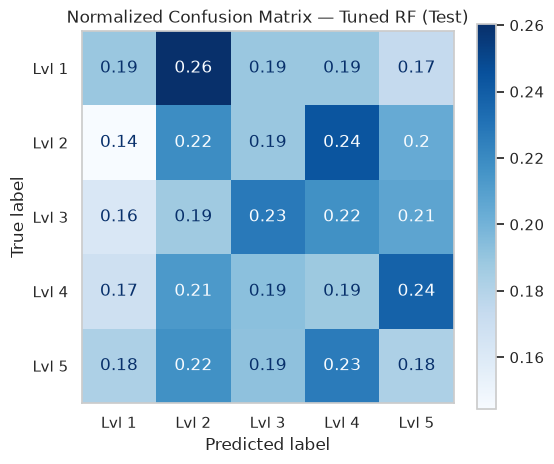

{'n_errors': np.int64(799), 'near_miss_rate': np.float64(0.4142678347934919), 'extreme_rate': np.float64(0.5857321652065082)}


In [37]:
# --- Predefined display settings ---
from matplotlib.pylab import fix


CM_NORMALIZE = "true"
CM_CMAP = "Blues"

# YOUR CODE HERE:
# 1. Define neighbour_error_stats(y_true, y_pred) returning dict with n_errors, near_miss_rate, extreme_rate
def neighbour_error_stats(y_true, y_pred):
    """Compute share of errors that are off-by-1 vs off-by-2+."""
    errors = np.asarray(y_true) != np.asarray(y_pred)
    gaps = np.abs(np.asarray(y_true) - np.asarray(y_pred))[errors]
    n_errors = np.sum(errors)
    near_miss_rate = np.sum(gaps == 1) / n_errors if n_errors > 0 else 0
    extreme_rate = np.sum(gaps >= 2) / n_errors if n_errors > 0 else 0
    return {'n_errors': n_errors, 'near_miss_rate': near_miss_rate, 'extreme_rate': extreme_rate}

# sanity = neighbour_error_stats([0, 0, 4], [1, 4, 4])  # 1 near-miss + 1 extreme
# print(sanity)

sanity = neighbour_error_stats([0, 0, 4], [1, 4, 4])  # 1 near-miss + 1 extreme
print(sanity)



fix, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=display_labels, normalize=CM_NORMALIZE, cmap=CM_CMAP, ax=ax)
ax.set_title('Normalized Confusion Matrix \u2014 Tuned RF (Test)')
plt.grid(False); plt.show()

# 2. Plot normalized confusion matrix on the Test set
# fig, ax = plt.subplots(figsize=(6, 5))
# ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, display_labels=display_labels, normalize=CM_NORMALIZE, cmap=CM_CMAP, ax=ax)
# ax.set_title('Normalized Confusion Matrix \u2014 Tuned RF (Test)')
# plt.grid(False); plt.show()

# 3. Run neighbour-error analysis on Test predictions
# stats = neighbour_error_stats(y_test, y_test_pred)
# print(stats)

stats = neighbour_error_stats(y_test, y_test_pred)
print(stats)


---
## 9. Summary & Next Steps

### 📝 Key Takeaways from Stages 6 & 7:
1. **Tuning protocol:** `StratifiedKFold(5)` + `GridSearchCV(scoring='f1_macro')` selected `best_params_` objectively without touching Test.
2. **Overfitting diagnosis:** Train-vs-Val Macro F1 gap quantifies memorisation vs generalisation.
3. **Honest estimate:** The single locked-Test Macro F1 is the README number.
4. **Explainability:** Impurity + permutation importances name the top lifestyle drivers; neighbour-error analysis shows whether mistakes are near-misses or extreme.

➡️ **Next Stage:** Section 8 \u2014 freeze the winning pipeline in `src/train.py` / `src/predict.py`, then build the Streamlit app!
